# Introduction




# Prepare for analysis

## Load packages

In [81]:
%pip install wordcloud
%pip install -U seaborn

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS

from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [82]:
# TODO: Add all hard coded parameters like file paths or model parameters here
TRAIN_PATH = "train.csv"
gender = "gender_submission.csv"
test = "test.csv"

## Read the data

In [83]:
train_df = pd.read_csv(TRAIN_PATH)

# TODO: Put the path at the top of the script and replace with variable
test_df = pd.read_csv("test.csv")
gender_df = pd.read_csv("gender_submission.csv")

# Preliminary data inspection

## Quick glimpse of the data
TODO: Think if you can abstract away much here.

In [84]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [85]:
# check the null values of the dataset
missing = train_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "percent": (missing / len(train_df) * 100).round(1)})

,missing,percent
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


In [86]:
test_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [87]:
# check the null values of the dataset
missing = test_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "percent": (missing / len(train_df) * 100).round(1)})

,missing,percent
Cabin,327,36.7
Age,86,9.7
Fare,1,0.1


In [88]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [89]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 52.8 KB


In [90]:
train_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [91]:
test_df.describe()

,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


## Few statistics on the data

### Missing data

In [92]:
# TODO: turn into function
def missing_data_summary(df):
    """
    Summarize missing values and dtypes for each column.
    """
    total = df.isnull().sum()
    percent = (df.isnull().sum()/df.isnull().count()*100)
    tt = pd.concat([total, percent], axis=1, keys=['Total', 'Percent'])
    types = []
    for col in df.columns:
        dtype = str(df[col].dtype)
        types.append(dtype)
    tt['Types'] = types
    df_missing = np.transpose(tt)
    return df_missing

df_missing_train = missing_data_summary(train_df)
df_missing_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,0,0,0,0,0,177,0,0,0,0,687,2
Percent,0.0,0.0,0.0,0.0,0.0,19.86532,0.0,0.0,0.0,0.0,77.104377,0.224467
Types,int64,int64,int64,str,str,float64,int64,int64,str,float64,str,str


In [93]:
# TODO: turn into function
# The same function above can be used
df_missing_test = missing_data_summary(test_df)
df_missing_test

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,0,0,0,0,86,0,0,0,1,327,0
Percent,0.0,0.0,0.0,0.0,20.574163,0.0,0.0,0.0,0.239234,78.229665,0.0
Types,int64,int64,str,str,float64,int64,int64,str,float64,str,str


##### Obervation 1: Notice that the testing dataset differs from the training data: the training dataset has an additional variable 'Survived'. However, the percentages of missing values are largely similar. 

### Most frequent data

In [94]:
# TODO: turn into function
def data_frequency(df):
    """
    list the frequency of the data 
    """
    total = df.count()
    tt = pd.DataFrame(total)
    tt.columns = ['Total']
    items = []
    vals = []
    for col in df.columns:
        try:
            itm = df[col].value_counts().index[0]
            val = df[col].value_counts().values[0]
            items.append(itm)
            vals.append(val)
        except Exception as ex:
            print(ex)
            items.append(0)
            vals.append(0)
            continue    
    tt['Most frequent item'] = items
    tt['Frequency'] = vals
    tt['Percent from total'] = np.round(vals / total * 100, 3)
    frequency_tbl = np.transpose(tt)
    return frequency_tbl

df_frequency_train = data_frequency(train_df)
df_frequency_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,891,891,891,891,891,714,891,891,891,891,204,889
Most frequent item,1,0,3,"Braund, Mr. Owen Harris",male,24.0,0,0,347082,8.05,G6,S
Frequency,1,549,491,1,577,30,608,678,7,43,4,644
Percent from total,0.112,61.616,55.107,0.112,64.759,4.202,68.238,76.094,0.786,4.826,1.961,72.441


In [95]:
# TODO: turn into function
df_frequency_test = data_frequency(test_df)
df_frequency_test

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,418,418,418,418,332,418,418,418,417,91,418
Most frequent item,892,3,"Kelly, Mr. James",male,21.0,0,0,PC 17608,7.75,B57 B59 B63 B66,S
Frequency,1,218,1,266,17,283,324,5,21,3,270
Percent from total,0.239,52.153,0.239,63.636,5.12,67.703,77.512,1.196,5.036,3.297,64.593


##### Observation 2: percentage of passengers embarked is higher by 8% in the training data

### Unique values

In [96]:
# TODO: turn into function
def unique_values_count(df):
    """
    display the unique values of each variable

    Args: 
        df: data to ingest
    returns:
        count_unique: count the number of unique observations for each variable
    """
    total = df.count()
    tt = pd.DataFrame(total)
    tt.columns = ['Total']
    uniques = []
    for col in df.columns:
        unique = df[col].nunique()
        uniques.append(unique)
    tt['Uniques'] = uniques
    count_unique = np.transpose(tt)
    return count_unique

df_unique_train = unique_values_count(train_df)
df_unique_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,891,891,891,891,891,714,891,891,891,891,204,889
Uniques,891,2,3,891,2,88,7,7,681,248,147,3


In [97]:
# TODO: turn into function
df_unique_test = unique_values_count(test_df)
df_unique_test

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,418,418,418,418,332,418,418,418,417,91,418
Uniques,418,3,418,2,79,7,8,363,169,76,3


# Exploratory data analysis

## Univariate analysis for all features


We show here two graphs in paralel:
* distribution of class values, split per Survived value
* comparison of class values, in train and test data


Let's first aggregate train and test data into one single dataframe, `all_df`.

In [98]:
# TODO: turn into function
def aggr(df1, df2):
    """ 
    combine two datasets into one

    """
    all_df = pd.concat([df1, df2], axis=0)
    all_df["set"] = "train"
    all_df.loc[all_df.Survived.isna(), "set"] = "test"
    return all_df

all_df = aggr(test_df, train_df)
all_df

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived,set
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,NaN,test
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,NaN,test
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,NaN,test
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,NaN,test
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,NaN,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,0.0,train
887,888,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,1.0,train
888,889,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,0.0,train
889,890,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,1.0,train


In [99]:
all_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived,set
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,NaN,test
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,NaN,test
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,NaN,test
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,NaN,test
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,NaN,test


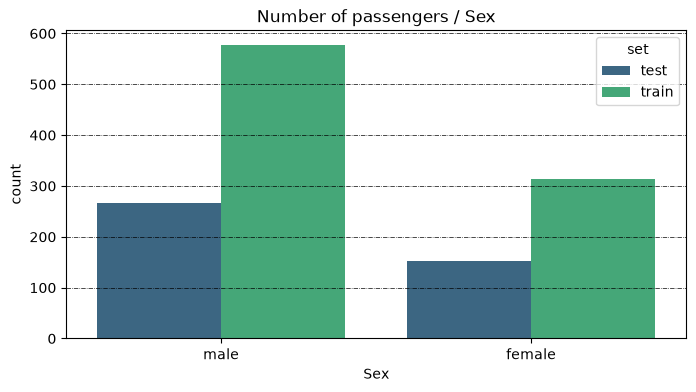

In [100]:
# Plot count pairs "Sex"
# ADDED: use viridis to define the colors
color_list = sns.color_palette("viridis", 2)
f, ax = plt.subplots(1, 1, figsize=(8, 4))
sns.countplot(x="Sex", data=all_df, hue="set", palette= color_list)
plt.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
ax.set_title("Number of passengers / Sex")
plt.show()  

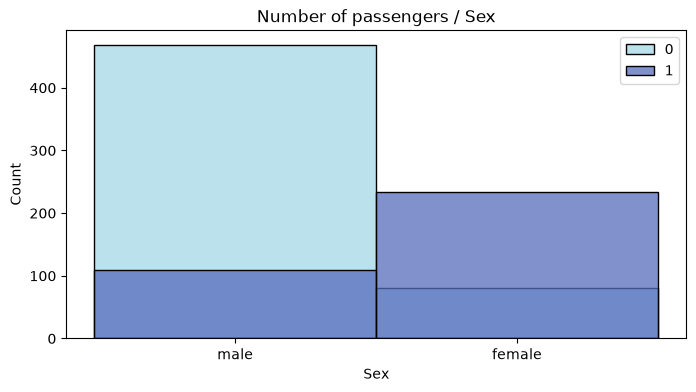

In [101]:
# Plot distribution pairs for "Sex" and hue as "Survived"
color_list = ["#A5D7E8", "#576CBC", "#19376D", "#0b2447"]
f, ax = plt.subplots(1, 1, figsize=(8, 4))
for i, h in enumerate(train_df["Survived"].unique()):
    g = sns.histplot(train_df.loc[train_df["Survived"]==h, "Sex"], 
                                  color=color_list[i], 
                                  ax=ax, 
                                  label=h)
ax.set_title("Number of passengers / Sex")
g.legend()
plt.show()

In [102]:
# Check the numbers of survival gender split
survival_gender_split = pd.crosstab(train_df["Sex"], train_df["Survived"])
survival_gender_split

Survived,0,1
Sex,,
female,81,233
male,468,109


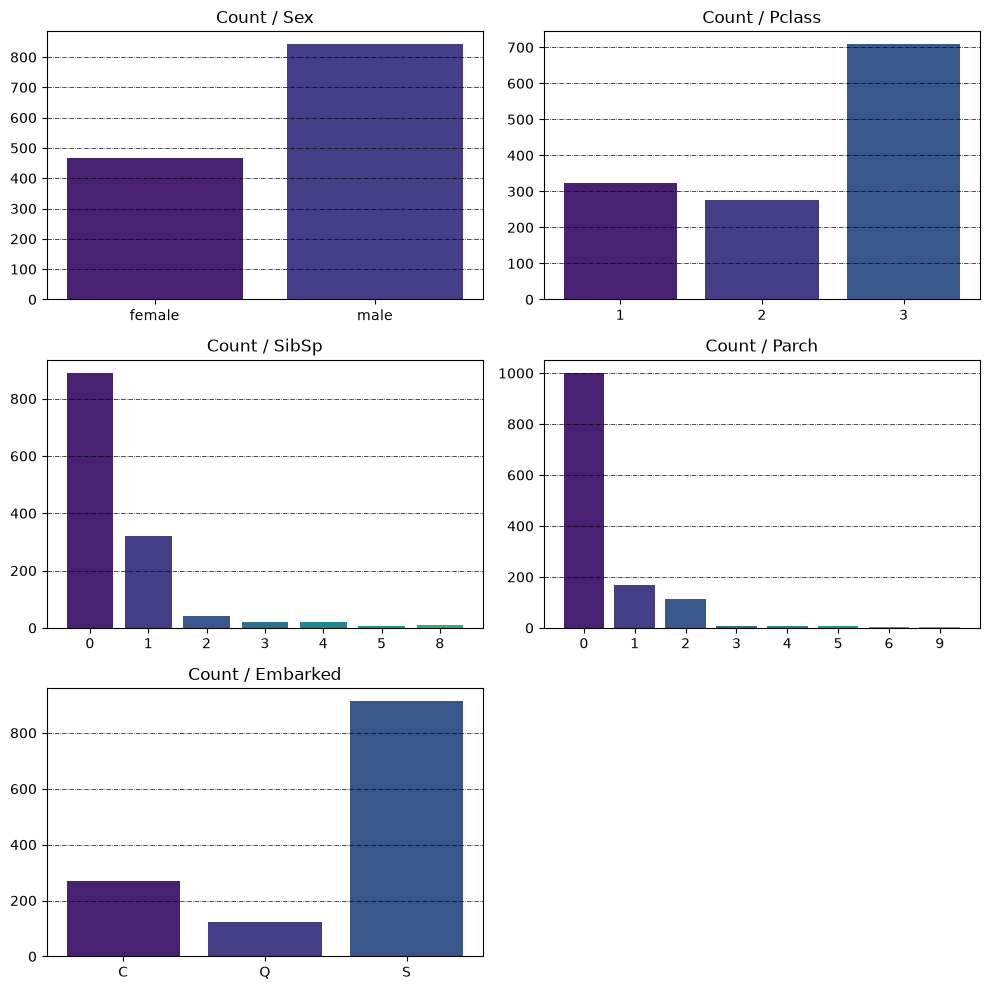

In [103]:
# Plot count pairs using all_df for the columns: Sex, Pclasss, SibSp, Parch, Embarked
color_list = sns.color_palette("viridis", 10)
cols = ["Sex", "Pclass", "SibSp", "Parch", "Embarked"]

fig, axes = plt.subplots(3, 2, figsize=(10, 10))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    counts = all_df[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color=color_list[:len(counts)])
    ax.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
    ax.set_title(f"Count / {col}")

axes[-1].remove()
plt.tight_layout()
plt.show()

##### Observation 3: potentially spurious parents count - an individual cannot have more than 2 parents!!!

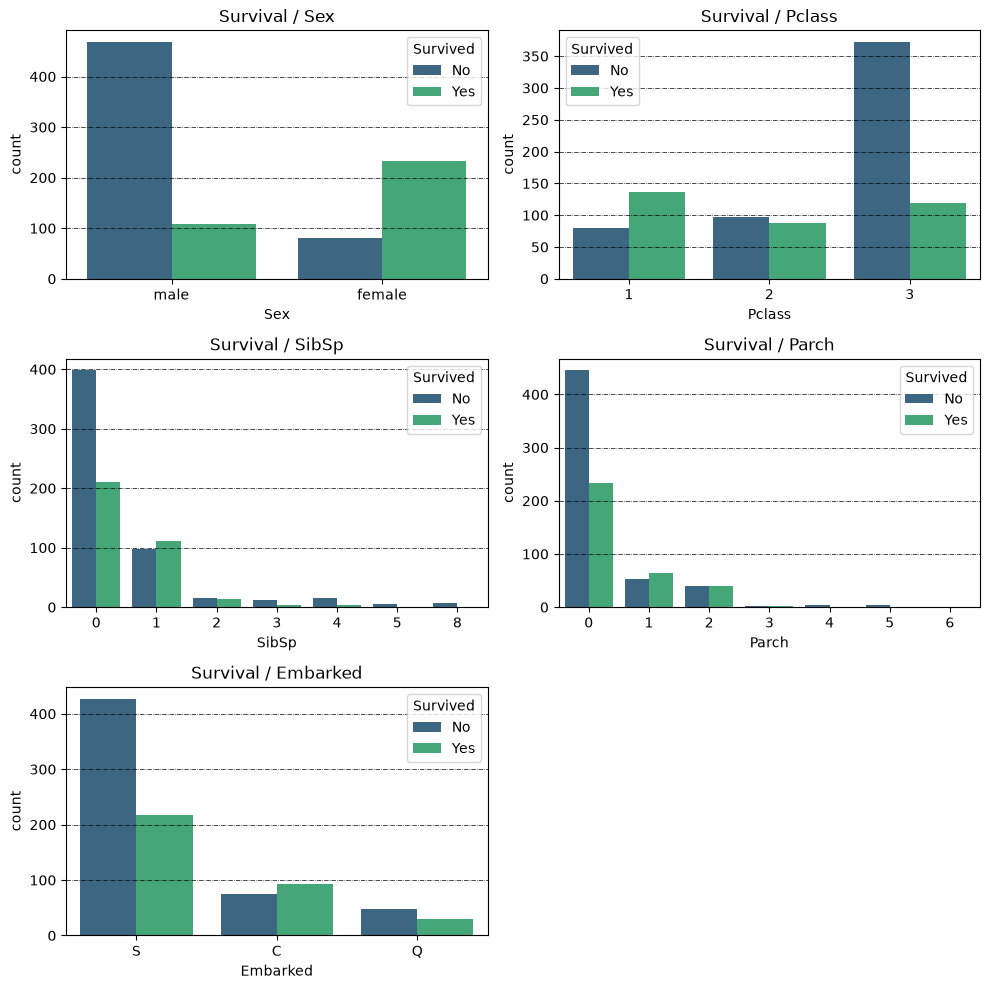

In [104]:
# Plot count pairs using all_df for the columns: Sex, Pclasss, SibSp, Parch, Embarked and use "Survived" as hue.
color_list = sns.color_palette("viridis", 2)
cols = ["Sex", "Pclass", "SibSp", "Parch", "Embarked"]

fig, axes = plt.subplots(3, 2, figsize=(10, 10))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.countplot(x=col, data=train_df, hue="Survived", palette=color_list, ax=ax)
    ax.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
    ax.set_title(f"Survival / {col}")
    ax.legend(title="Survived", labels=["No", "Yes"])

axes[-1].remove()  # drop the unused 6th panel
plt.tight_layout()
plt.show()

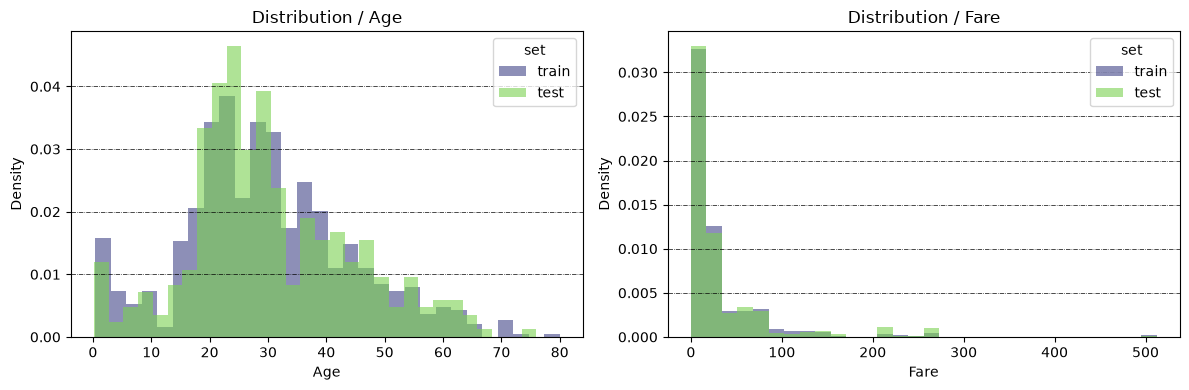

In [105]:
# Plot distribution pairs for Age and Fare
cols = ["Age", "Fare"]
import matplotlib as mpl
colors = [mpl.colormaps["viridis"](x) for x in (0.2, 0.8)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, cols):
    for set_name, color in zip(["train", "test"], colors):
        values = all_df.loc[all_df["set"] == set_name, col].dropna()
        ax.hist(values, bins=30, density=True, alpha=0.6, color=color, label=set_name)
    ax.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
    ax.set_title(f"Distribution / {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.legend(title="set")

plt.tight_layout()
plt.show()



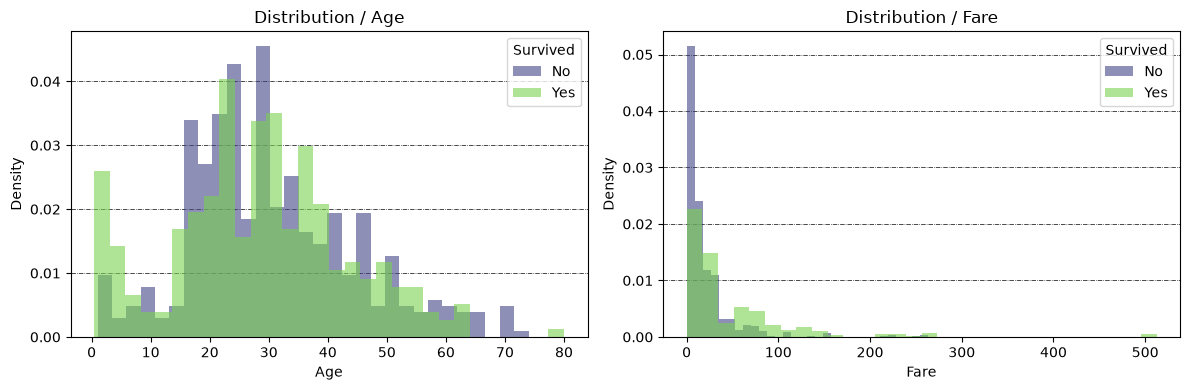

In [106]:
# Plot distribution pairs for Age and Fare using "Survived" as hue

cols = ["Age", "Fare"]
colors = [mpl.colormaps["viridis"](x) for x in (0.2, 0.8)]
labels = {0: "No", 1: "Yes"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, cols):
    for survived, color in zip([0, 1], colors):
        values = all_df.loc[all_df["Survived"] == survived, col].dropna()
        ax.hist(values, bins=30, density=True, alpha=0.6, color=color, label=labels[survived])
    ax.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
    ax.set_axisbelow(True)
    ax.set_title(f"Distribution / {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.legend(title="Survived")

plt.tight_layout()
plt.show()

#### Observation 4: younger passengers and passengers with higher fare are more likely to survive.

## Family size


Based on SibSp (sibilings or spouse) and Parch (parents or children), we set the Family Size field.

In [107]:
# TODO: turn into function
def add_family_size (df):
    """
    create a new variable that counts the family size
    """
    df["Family Size"] = df["SibSp"] + df["Parch"] + 1
    return df

all_df = add_family_size(all_df)
all_df

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived,set,Family Size
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,NaN,test,1
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,NaN,test,2
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,NaN,test,1
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,NaN,test,1
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,NaN,test,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,0.0,train,1
887,888,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,1.0,train,1
888,889,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,0.0,train,4
889,890,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,1.0,train,1


In [108]:
# TODO: turn into function
train_df = add_family_size(train_df)
train_df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,1
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,1
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,4
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,1


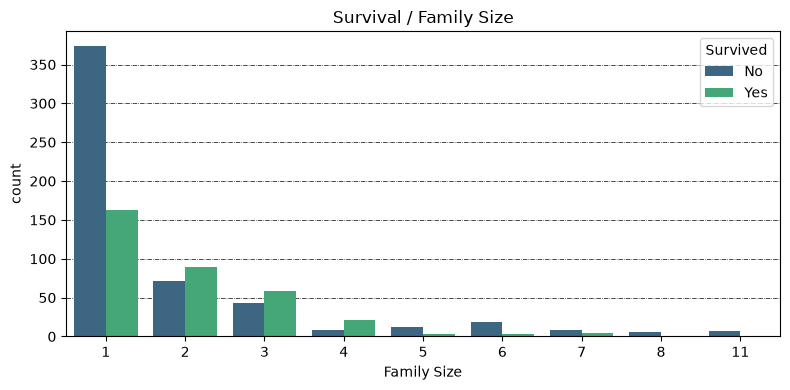

In [109]:
# Plot count pairs using all_df for the column "Family Size" and use "Survived" as hue.
color_list = sns.color_palette("viridis", 2)

plot_df = all_df.dropna(subset=["Survived"]).copy()
plot_df["Survived"] = plot_df["Survived"].astype(int)

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
sns.countplot(x="Family Size", data=plot_df, hue="Survived", palette=color_list, ax=ax)
ax.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
ax.set_axisbelow(True)
ax.set_title("Survival / Family Size")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["No", "Yes"], title="Survived")
plt.tight_layout()
plt.show()

##### Observation 5: individuals from medium familiy size with 2-4 are more likely to survive - potentially because these individuals are the younger siblings/kids of the parents who are prioritise for the safety boats. However, without controling for other variables it is not clear.

## Age interval

In [110]:
# TODO: turn into function
def add_age_interval(df, bins=(-np.inf, 16, 32, 48, 64, np.inf), col="Age", new_col="Age Interval"):
    """
    Add a column that assigns each age to an interval code (0, 1, 2, ...).

    Intervals are right-inclusive: (-inf, 16] -> 0, (16, 32] -> 1,
    (32, 48] -> 2, (48, 64] -> 3, (64, inf) -> 4. Missing ages stay NaN.

    Args:
        df (pd.DataFrame): Data containing the age column.
        bins (sequence): Bin edges, including the outer bounds.
        col (str): Name of the age column.
        new_col (str): Name of the column to create.

    Returns:
        pd.DataFrame: A copy of df with the new column added.
    """
    df = df.copy()
    df[new_col] = pd.cut(df[col], bins=bins, labels=False)
    return df

all_df = add_age_interval(all_df)
all_df

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived,set,Family Size,Age Interval
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,NaN,test,1,2.0
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,NaN,test,2,2.0
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,NaN,test,1,3.0
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,NaN,test,1,1.0
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,NaN,test,3,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,0.0,train,1,1.0
887,888,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,1.0,train,1,1.0
888,889,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,0.0,train,4,NaN
889,890,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,1.0,train,1,1.0


In [111]:
# TODO: turn into function
train_df = add_age_interval(train_df)
train_df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size,Age Interval
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,1.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,2.0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,1.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,2.0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,1,1.0
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,1,1.0
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,4,NaN
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,1,1.0


In [112]:
all_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived,set,Family Size,Age Interval
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,NaN,test,1,2.0
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,NaN,test,2,2.0
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,NaN,test,1,3.0
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,NaN,test,1,1.0
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,NaN,test,3,1.0


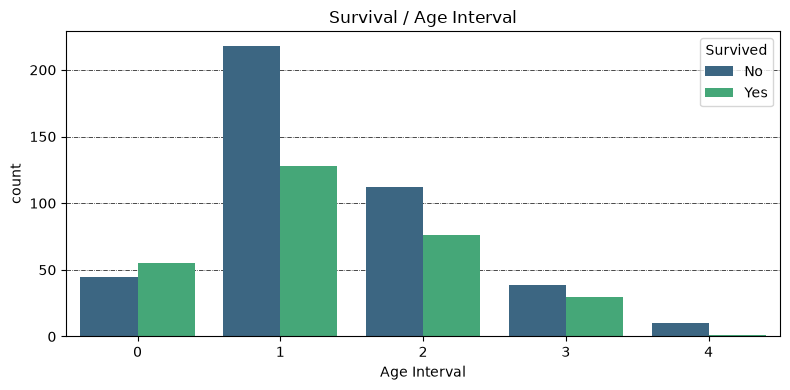

In [113]:
# Plot count pairs using all_df for the column "Age Interval" and use "Survived" as hue.
color_list = sns.color_palette("viridis", 2)

plot_df = all_df.dropna(subset=["Survived", "Age Interval"]).copy()
plot_df["Survived"] = plot_df["Survived"].astype(int)
plot_df["Age Interval"] = plot_df["Age Interval"].astype(int)

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
sns.countplot(x="Age Interval", data=plot_df, hue="Survived", palette=color_list, ax=ax)
ax.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
ax.set_axisbelow(True)
ax.set_title("Survival / Age Interval")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["No", "Yes"], title="Survived")
plt.tight_layout()
plt.show()

##### Obervation 6: in line with observation 4, younger people are more likely to survive

## Fare interval

In [114]:
# TODO: turn into function
def add_fare_interval(df, bins=(-np.inf, 7.91, 14.454, 31, np.inf), col="Fare", new_col="Fare Interval"):
    """
    Add a column that assigns each fare to an interval code (0, 1, 2, 3).

    Args:
        df (pd.DataFrame): Data containing the fare column.
        bins (sequence): Bin edges, including the outer bounds.
        col (str): Name of the fare column.
        new_col (str): Name of the column to create.

    Returns:
        pd.DataFrame: A copy of df with the new column added.
    """
    df = df.copy()
    df[new_col] = pd.cut(df[col], bins=bins, labels=False)
    return df

all_df = add_fare_interval(all_df)
all_df

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived,set,Family Size,Age Interval,Fare Interval
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,NaN,test,1,2.0,0.0
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,NaN,test,2,2.0,0.0
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,NaN,test,1,3.0,1.0
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,NaN,test,1,1.0,1.0
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,NaN,test,3,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,0.0,train,1,1.0,1.0
887,888,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,1.0,train,1,1.0,2.0
888,889,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,0.0,train,4,NaN,2.0
889,890,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,1.0,train,1,1.0,2.0


In [115]:
# TODO: turn into function
train_df = add_fare_interval(train_df)
train_df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size,Age Interval,Fare Interval
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,1.0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,2.0,3
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,1.0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,2.0,3
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,2.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,1,1.0,1
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,1,1.0,2
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,4,NaN,2
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,1,1.0,2


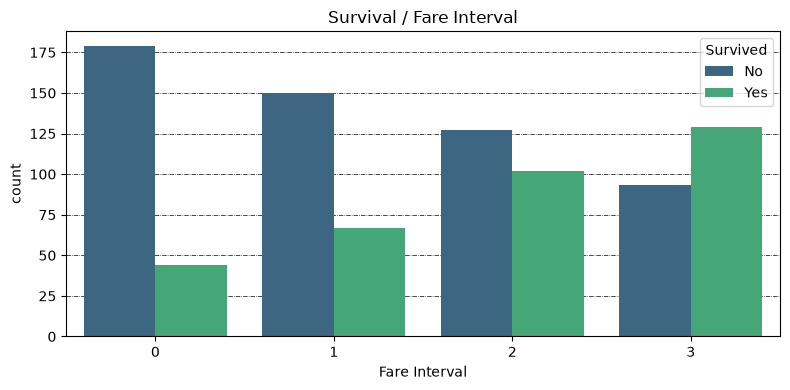

In [116]:
# Plot count pairs using all_df for the column "Fare Interval"
color_list = sns.color_palette("viridis", 2)

plot_df = all_df.dropna(subset=["Survived", "Fare Interval"]).copy()
plot_df["Survived"] = plot_df["Survived"].astype(int)
plot_df["Fare Interval"] = plot_df["Fare Interval"].astype(int)

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
sns.countplot(x="Fare Interval", data=plot_df, hue="Survived", palette=color_list, ax=ax)
ax.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
ax.set_axisbelow(True)
ax.set_title("Survival / Fare Interval")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["No", "Yes"], title="Survived")
plt.tight_layout()
plt.show()

##### Obervation 7: in line with observation 4, richer people (people with higer fare) are more likely to survive

Let's create a composed feature: Pclass + Sex.

In [117]:
# TODO: turn into function
def add_sex_pclass(df, new_col="Sex_Pclass"):
    """
    Add a column combining sex initial and passenger class, e.g. "M_C3" or "F_C1".

    Args:
        df (pd.DataFrame): Data containing "Sex" and "Pclass" columns.
        new_col (str): Name of the column to create.

    Returns:
        pd.DataFrame: A copy of df with the new column added.
    """
    df = df.copy()
    df[new_col] = df["Sex"].str[0].str.upper() + "_C" + df["Pclass"].astype(str)
    return df

train_df = add_sex_pclass(train_df)

In [118]:
# TODO: turn into function
all_df = add_sex_pclass(all_df)

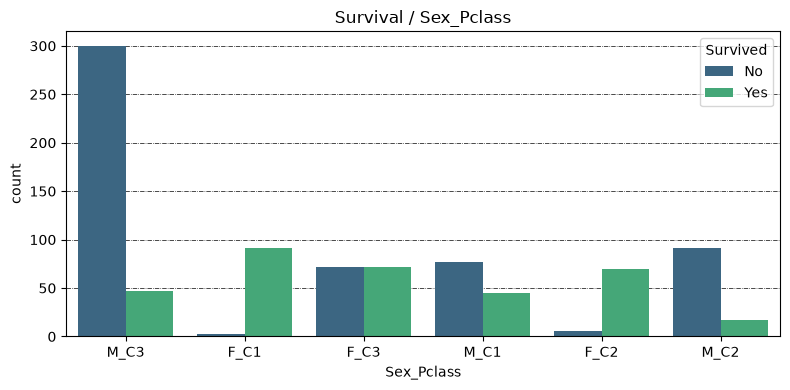

In [119]:
# Plot count pairs using all_df for the column "Fare Interval" and "Fare (grouped by survival)" with "Survived" as hue
color_list = sns.color_palette("viridis", 2)

plot_df = all_df.dropna(subset=["Survived", "Sex_Pclass"]).copy()
plot_df["Survived"] = plot_df["Survived"].astype(int)
plot_df["Sex_Pclass"] = plot_df["Sex_Pclass"]

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
sns.countplot(x="Sex_Pclass", data=plot_df, hue="Survived", palette=color_list, ax=ax)
ax.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
ax.set_axisbelow(True)
ax.set_title("Survival / Sex_Pclass")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["No", "Yes"], title="Survived")
plt.tight_layout()
plt.show()

##### Obervation 8: the gender advantage of female increases as fare class falls, meaning that male lower classes passengers are significantly disadvantaged when it comes to survival.

## Process names


When we process names, we would like to extract the following information:

- Family name - this is the first word (or few first words, if a family name with multiple names), followed by a comma  
- Title - this follows just after the comma   
- Given name - this is the word or group of words following family name  
- Maiden name - for ladies, is given between parantheses  

We start with creating a function that parses the Name string and extract (if possible) these 4 elements


In [120]:
# TODO: also move this function to a separate file
from parse_names import parse_names

all_df = add_fare_interval(all_df)
    

In [128]:
# TODO: turn into function
def add_name_features(df, name_cols=("Family Name", "Title", "Given Name", "Maiden Name")):
    """
    Parse each passenger's name and add the parts as new columns.

    Relies on `parse_names(row)`, which must return 4 values in this order:
    family name, title, given name, maiden name.

    Args:
        df (pd.DataFrame): Data containing a "Name" column.
        name_cols (tuple[str]): Names of the 4 columns to create.

    Returns:
        pd.DataFrame: A copy of df with the name columns added.
    """
    df = df.copy()
    df[list(name_cols)] = df.apply(lambda row: parse_names(row), axis=1)
    return df

all_df = add_name_features(all_df)
all_df

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,...,set,Family Size,Age Interval,Fare Interval,Sex_Pclass,Family Name,Title,Given Name,Maiden Name,Family Type
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,...,test,1,2.0,0.0,M_C3,Kelly,Mr.,James,NaN,1
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,...,test,2,2.0,0.0,F_C3,Wilkes,Mrs.,James,Ellen Needs,2
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,...,test,1,3.0,1.0,M_C2,Myles,Mr.,Thomas Francis,NaN,1
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,...,test,1,1.0,1.0,M_C3,Wirz,Mr.,Albert,NaN,1
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,...,test,3,1.0,1.0,F_C3,Hirvonen,Mrs.,Alexander,Helga E Lindqvist,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,...,train,1,1.0,1.0,M_C2,Montvila,Rev.,Juozas,NaN,1
887,888,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,...,train,1,1.0,2.0,F_C1,Graham,Miss.,Margaret Edith,NaN,1
888,889,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,...,train,4,NaN,2.0,F_C3,Johnston,Miss.,"Catherine Helen ""Carrie""",NaN,4
889,890,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,...,train,1,1.0,2.0,M_C1,Behr,Mr.,Karl Howell,NaN,1


In [129]:
# TODO: turn into function
train_df = add_name_features(train_df)

## Multivariate analysis


Let's look now to the interaction of multiple features.

C:\Users\szhu\AppData\Local\Temp\ipykernel_22956\2596741963.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["≤16", "17-32", "33-48", "49-64", ">64"])


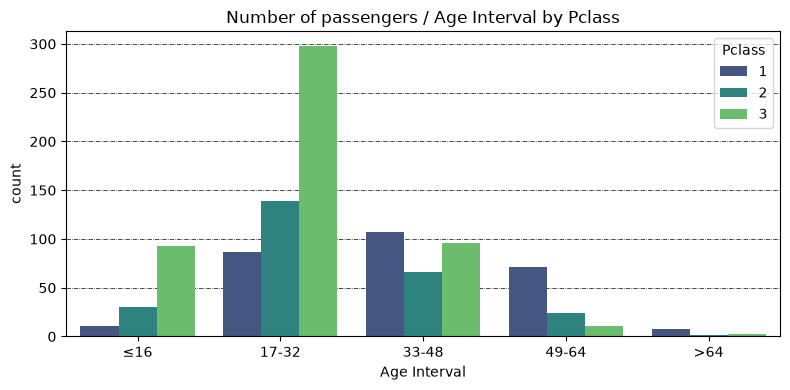

In [130]:
# TODO: Plot count pairs of "Age Interval" grouped by "Pclass"

color_list = sns.color_palette("viridis", 3)

plot_df = all_df.dropna(subset=["Age Interval"]).copy()
plot_df["Age Interval"] = plot_df["Age Interval"].astype(int)

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
sns.countplot(x="Age Interval", data=plot_df, hue="Pclass", palette=color_list, ax=ax)
ax.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
ax.set_axisbelow(True)
ax.set_title("Number of passengers / Age Interval by Pclass")
ax.set_xticklabels(["≤16", "17-32", "33-48", "49-64", ">64"])
ax.legend(title="Pclass")
plt.tight_layout()
plt.show()

C:\Users\szhu\AppData\Local\Temp\ipykernel_22956\1233262366.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["≤16", "17-32", "33-48", "49-64", ">64"])


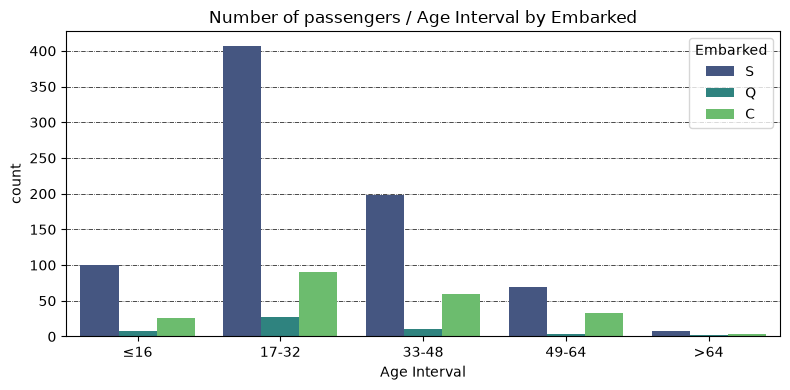

In [131]:
# TODO: Plot count pairs of "Age Interval" grouped by "Embarked"
color_list = sns.color_palette("viridis", 3)

plot_df = all_df.dropna(subset=["Age Interval"]).copy()
plot_df["Age Interval"] = plot_df["Age Interval"].astype(int)

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
sns.countplot(x="Age Interval", data=plot_df, hue="Embarked", palette=color_list, ax=ax)
ax.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
ax.set_axisbelow(True)
ax.set_title("Number of passengers / Age Interval by Embarked")
ax.set_xticklabels(["≤16", "17-32", "33-48", "49-64", ">64"])
ax.legend(title="Embarked")
plt.tight_layout()
plt.show()

C:\Users\szhu\AppData\Local\Temp\ipykernel_22956\4232627792.py:8: UserWarning: 
The palette list has fewer values (3) than needed (4) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(x="Pclass", data=plot_df, hue="Fare Interval", palette=color_list, ax=ax)


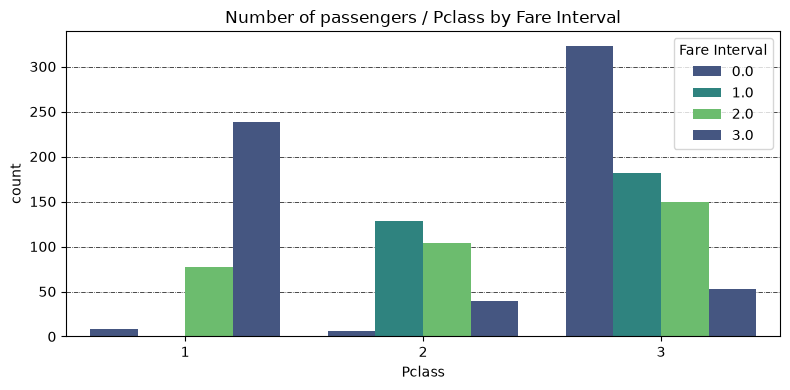

In [134]:
# TODO: Plot count pairs of "Pclass" grouped by "Fare Interval"
color_list = sns.color_palette("viridis", 3)

plot_df = all_df.dropna(subset=["Pclass"]).copy()
plot_df["Pclass"] = plot_df["Pclass"].astype(int)

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
sns.countplot(x="Pclass", data=plot_df, hue="Fare Interval", palette=color_list, ax=ax)
ax.grid(color="black", linestyle="-.", linewidth=0.5, axis="y", which="major")
ax.set_axisbelow(True)
ax.set_title("Number of passengers / Pclass by Fare Interval")
ax.legend(title="Fare Interval")
plt.tight_layout()
plt.show()

### Few more engineered data 


Let's create two more engineered features:  
* Family size interval: Single, Small, Large  
* Aggregated titles: Mr, Mrs, Master, Miss, and Rare  

In [135]:
# TODO: turn into function
def add_family_type(df, new_col="Family Type"):
    """
    Add a "Family Type" column based on "Family Size".

    Args:
        df (pd.DataFrame): Data containing a "Family Size" column.
        new_col (str): Name of the column to create.

    Returns:
        pd.DataFrame: A copy of df with the new column added.
    """
    df = df.copy()
    df[new_col] = df["Family Size"]
    return df

all_df = add_family_type(all_df)
train_df = add_family_type(train_df)

In [137]:
def add_family_type(df, new_col="Family Type"):
    """
    Group "Family Size" into a "Family Type" category.

    1 -> "Single", 2-4 -> "Small", 5 or more -> "Large".

    Args:
        df (pd.DataFrame): Data containing a "Family Size" column.
        new_col (str): Name of the column to create (overwritten if it exists).

    Returns:
        pd.DataFrame: A copy of df with the new column added.
    """
    df = df.copy()
    df[new_col] = np.select(
        [df["Family Size"] == 1, df["Family Size"] < 5],
        ["Single", "Small"],
        default="Large",
    )
    return df

all_df = add_family_type(all_df)
train_df = add_family_type(train_df)

In [138]:
for dataset in [all_df, train_df]:
    dataset["Titles"] = dataset["Title"]

In [139]:
# TODO: turn into function
def unify_titles(df, col="Titles"):
    """
    Group rare and alternative titles into a smaller set of categories.
    Args:
        df (pd.DataFrame): Data containing the title column.
        col (str): Name of the title column to clean.

    Returns:
        pd.DataFrame: A copy of df with the titles unified.
    """
    title_map = {
        "Mlle.": "Miss.",
        "Ms.": "Miss.",
        "Mme.": "Mrs.",
        **{t: "Rare" for t in ["Lady.", "the Countess.", "Capt.", "Col.", "Don.",
                               "Dr.", "Major.", "Rev.", "Sir.", "Jonkheer.", "Dona."]},
    }
    df = df.copy()
    df[col] = df[col].replace(title_map)
    return df

all_df = unify_titles(all_df)
train_df = unify_titles(train_df)

In [ ]:
# TODO: turn into function
def survival_rate_by(df, group_cols, target="Survived"):
    """
    Compute the mean of the target column (survival rate) for each group.

    """
    return df[group_cols + [target]].groupby(group_cols, as_index=False).mean()

survival_rate_by(train_df, ["Titles", "Sex"])

,Titles,Sex,Survived
0,Master.,male,0.575000
1,Miss.,female,0.702703
2,Mr.,male,0.156673
3,Mrs.,female,0.793651
4,Rare,female,1.000000
5,Rare,male,0.250000


# Baseline model

## Feature engineering: Map categorical value to numerical values

In [148]:
# TODO: turn into function
def assign_gender (df1, df2):
    """
    Assign the gender to numerical values
    """
    results =[]
    for dataset in [df1, df2]:
        dataset = dataset.copy()
        dataset['Sex'] = dataset['Sex'].map( {'female': 1, 'male': 0} ).astype(int)
        results.append(dataset)
    return tuple(results)

train_df, test_df = assign_gender(train_df, test_df)

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer.Replace or remove non-finite values or cast to an integer typethat supports these values (e.g. 'Int64')

Create train-validation split.

In [149]:
train_df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Family Size,Age Interval,Fare Interval,Sex_Pclass,Family Name,Title,Given Name,Maiden Name,Family Type,Titles
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,...,2,1.0,0,M_C3,Braund,Mr.,Owen Harris,NaN,Small,Mr.
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,...,2,2.0,3,F_C1,Cumings,Mrs.,John Bradley,Florence Briggs Thayer,Small,Mrs.
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,...,1,1.0,1,F_C3,Heikkinen,Miss.,Laina,NaN,Single,Miss.
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,...,2,2.0,3,F_C1,Futrelle,Mrs.,Jacques Heath,Lily May Peel,Small,Mrs.
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,...,1,2.0,1,M_C3,Allen,Mr.,William Henry,NaN,Single,Mr.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",0,27.0,0,0,211536,13.0000,...,1,1.0,1,M_C2,Montvila,Rev.,Juozas,NaN,Single,Rare
887,888,1,1,"Graham, Miss. Margaret Edith",1,19.0,0,0,112053,30.0000,...,1,1.0,2,F_C1,Graham,Miss.,Margaret Edith,NaN,Single,Miss.
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",1,NaN,1,2,W./C. 6607,23.4500,...,4,NaN,2,F_C3,Johnston,Miss.,"Catherine Helen ""Carrie""",NaN,Small,Miss.
889,890,1,1,"Behr, Mr. Karl Howell",0,26.0,0,0,111369,30.0000,...,1,1.0,2,M_C1,Behr,Mr.,Karl Howell,NaN,Single,Mr.


In [150]:
VALID_SIZE = 0.2
train, valid = train_test_split(train_df, test_size=VALID_SIZE, random_state=42, shuffle=True)

Define predictor features and target feature.

In [151]:
predictors = ["Sex", "Pclass"]
target = 'Survived'

Define the training and validation data and labels.

In [153]:
# TODO: turn into function
def split_features_target(df, predictors, target):
    """
    Split a DataFrame into features and target.

    Args:
        df (pd.DataFrame): Data containing the predictor and target columns.
        predictors (list[str]): Names of the feature columns.
        target (str): Name of the target column.

    Returns:
        tuple[pd.DataFrame, np.ndarray]: Feature DataFrame (X) and target values (y).
    """
    return df[predictors], df[target].values

train_X, train_Y = split_features_target(train, predictors, target)
valid_X, valid_Y = split_features_target(valid, predictors, target)

Initialize the classifiction algorithm.

In [156]:
# TODO: could this and the following code cells be turned into a function that returns the prediction?

clf = RandomForestClassifier(n_jobs=-1, 
                             random_state=42,
                             criterion="gini",
                             n_estimators=100,
                             verbose=False)

def random_forest_classification(train_X, train_Y, valid_X, n_jobs=-1, random_state=42,
                                 criterion="gini", n_estimators=100, verbose=False):
    """
    Train a random forest classifier and predict on the validation features.

    Args:
        train_X (pd.DataFrame): Training features.
        train_Y (np.ndarray): Training target values.
        valid_X (pd.DataFrame): Validation features to predict on.
        n_jobs (int): Number of parallel jobs (-1 uses all cores).
        random_state (int): Seed for reproducibility.
        criterion (str): Split quality measure ("gini" or "entropy").
        n_estimators (int): Number of trees.
        verbose (bool or int): Verbosity of the training output.

    Returns:
        tuple: The fitted model (clf) and the predictions on valid_X (preds).
    """
    clf = RandomForestClassifier(n_jobs=n_jobs, random_state=random_state,
                                 criterion=criterion, n_estimators=n_estimators,
                                 verbose=verbose)
    clf.fit(train_X, train_Y)
    preds = clf.predict(valid_X)
    return clf, preds

clf, preds = random_forest_classification(train_X, train_Y, valid_X)

Fit the classifier with the training data.

In [157]:
clf.fit(train_X, train_Y)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

Predict the train data (to check the training classification error).

In [158]:
preds_tr = clf.predict(train_X)

Predict the validation data.

In [159]:
preds = clf.predict(valid_X)

# Evaluation

## Classification report for training data.

In [160]:
print(metrics.classification_report(train_Y, preds_tr, target_names=['Not Survived', 'Survived']))

              precision    recall  f1-score   support

Not Survived       0.75      0.99      0.86       444
    Survived       0.96      0.47      0.63       268

    accuracy                           0.79       712
   macro avg       0.86      0.73      0.74       712
weighted avg       0.83      0.79      0.77       712



Classification report for validation data.

In [161]:
print(metrics.classification_report(valid_Y, preds, target_names=['Not Survived', 'Survived']))

              precision    recall  f1-score   support

Not Survived       0.73      0.96      0.83       105
    Survived       0.90      0.49      0.63        74

    accuracy                           0.77       179
   macro avg       0.81      0.72      0.73       179
weighted avg       0.80      0.77      0.75       179

